In [1]:
#Import libraries and configure file paths
 
from pathlib import Path
import duckdb

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() in ["notebooks", "data"]:
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data"

con = duckdb.connect()

# Input files
cards_file = DATA_DIR / "cards_data.csv"
transaction_file = DATA_DIR / "transactions_data.csv"
labels_file = DATA_DIR / "train_fraud_labels.json"
mcc_file = DATA_DIR / "mcc_codes.json"

# Intermediate and final output files
labels_csv = DATA_DIR / "fraud_labels.csv"
debit_output = DATA_DIR / "debit_fraud_dataset.csv"


# Verify input files
print("Current directory:", CURRENT_DIR)
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

for name, path in {
    "Cards": cards_file,
    "Transactions": transaction_file,
    "Fraud labels": labels_file,
    "MCC codes": mcc_file
}.items():
    print(f"{name}: {path.exists()}")

Current directory: c:\kavya\redischool\fraud detection\data
Project directory: c:\kavya\redischool\fraud detection
Data directory: c:\kavya\redischool\fraud detection\data
Cards: True
Transactions: True
Fraud labels: True
MCC codes: True


In [2]:
# Check for source files
files = {
    "Cards":     cards_file,
    "Transactions": transaction_file,
    "Fraud labels": labels_file,
    "MCC codes": mcc_file
}

for name, path in files.items():
    print(f"{name}: {path.exists()}")

Cards: True
Transactions: True
Fraud labels: True
MCC codes: True


In [3]:
print("Files available in data folder:")

for file in DATA_DIR.iterdir():
    print(file.name)

Files available in data folder:
01_exploratory_data_analysis.ipynb
cards_data.csv
debit_fraud_dataset.csv
fraud_labels.csv
mcc_codes.json
test.txt
train_fraud_labels.json
transactions_data.csv
users_data.csv


In [4]:
card_summary = con.execute(f"""
    SELECT
        card_type,
        COUNT(*) AS total_cards
    FROM read_csv_auto('{cards_file}')
    GROUP BY card_type
    ORDER BY total_cards DESC
""").df()

display(card_summary)

,card_type,total_cards
0,Debit,3511
1,Credit,2057
2,Debit (Prepaid),578


In [5]:
transaction_methods = con.execute(f"""
    SELECT
        use_chip,
        COUNT(*) AS total_transactions
    FROM read_csv(
        '{transaction_file}',
        header = true,
        auto_detect = true,
        strict_mode = false,
        null_padding = true
    )
    GROUP BY use_chip
    ORDER BY total_transactions DESC
""").df()

display(transaction_methods)

,use_chip,total_transactions
0,Swipe Transaction,6967185
1,Chip Transaction,4780818
2,Online Transaction,1557912


In [6]:
debit_summary = con.execute(f"""
    SELECT
        c.card_type,
        COUNT(*) AS total_transactions
    FROM read_csv(
        '{transaction_file}',
        header = true,
        quote = '"',
        escape = '"',
        strict_mode = false,
        null_padding = true
    ) t
    JOIN read_csv_auto('{cards_file}') c
        ON t.card_id = c.id
    GROUP BY c.card_type
    ORDER BY total_transactions DESC
""").df()

display(debit_summary)

,card_type,total_transactions
0,Debit,8280996
1,Credit,4109189
2,Debit (Prepaid),915730


```json
{
    "target": {
        "10649266": "No",
        "23410063": "No"
    }
}
```

In [7]:
# Read fraud labels from JSON
import json
from collections import Counter


with open(labels_file, "r") as f:
    fraud_data = json.load(f)

labels = fraud_data["target"]

print("Total labelled transactions:", len(labels))
print("\nFraud label distribution:")
print(Counter(labels.values()))

Total labelled transactions: 8914963

Fraud label distribution:
Counter({'No': 8901631, 'Yes': 13332})


In [8]:
#Export fraud labels to CSV
import csv

with open(labels_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)

    writer.writerow(["transaction_id", "fraud_label"])
    writer.writerows(labels.items())

print("Labels exported successfully:", labels_csv)

Labels exported successfully: c:\kavya\redischool\fraud detection\data\fraud_labels.csv


In [29]:
fraud_by_card = con.execute(f"""
    SELECT
        c.card_type,
        COUNT(*) AS labelled_transactions,

        SUM(CASE WHEN l.fraud_label = 'Yes'
            THEN 1 ELSE 0 END) AS fraud_transactions,

        SUM(CASE WHEN l.fraud_label = 'No'
            THEN 1 ELSE 0 END) AS genuine_transactions,

        ROUND(
            100.0 * SUM(CASE WHEN l.fraud_label = 'Yes'
                THEN 1 ELSE 0 END) / COUNT(*), 4
        ) AS fraud_percentage

    FROM read_csv(
        '{transaction_file}',
        header = true,
        quote = '"',
        escape = '"',
        strict_mode = false,
        null_padding = true
    ) t

    JOIN read_csv_auto('{cards_file}') c
        ON t.card_id = c.id

    JOIN read_csv_auto('{labels_csv}') l
        ON CAST(t.id AS VARCHAR) = l.transaction_id

    GROUP BY c.card_type
    ORDER BY c.card_type
""").df()

# Display results without the Pandas index
display(fraud_by_card.to_string(index=False))

'      card_type  labelled_transactions  fraud_transactions  genuine_transactions  fraud_percentage\n         Credit                2753467              4490.0             2748977.0            0.1631\n          Debit                5548196              7464.0             5540732.0            0.1345\nDebit (Prepaid)                 613300              1378.0              611922.0            0.2247'

In [10]:
#Create the final debit fraud dataset
con.execute(f"""
    COPY (
        SELECT
            t.id AS transaction_id,
            t.date,
            t.client_id,
            t.card_id,
            TRY_CAST(REPLACE(t.amount, '$', '') AS DOUBLE) AS amount,
            t.use_chip,
            t.merchant_id,
            t.merchant_city,
            t.merchant_state,
            t.mcc,
            t.errors,
            l.fraud_label

        FROM read_csv(
            '{transaction_file}',
            header = true,
            quote = '"',
            escape = '"',
            strict_mode = false,
            null_padding = true
        ) t

        JOIN read_csv_auto('{cards_file}') c
            ON t.card_id = c.id

        JOIN read_csv_auto('{labels_csv}') l
            ON CAST(t.id AS VARCHAR) = l.transaction_id

        WHERE c.card_type = 'Debit'
    )
    TO '{debit_output}'
    (HEADER, DELIMITER ',')
""")

print("Debit dataset exported successfully!")

Debit dataset exported successfully!


In [11]:

debit_validation = con.execute(f"""
    SELECT
        COUNT(*) AS total_transactions,
        COUNT(DISTINCT transaction_id) AS unique_transactions,
        COUNT(*) FILTER (WHERE fraud_label = 'Yes') AS fraud_transactions,
        COUNT(*) FILTER (WHERE fraud_label = 'No') AS genuine_transactions,
        COUNT(*) FILTER (WHERE amount IS NULL) AS missing_amounts
    FROM read_csv_auto('{debit_output}')
""").df()

display(debit_validation)

fraud_distribution = con.execute(f"""
    SELECT
        fraud_label,
        COUNT(*) AS transaction_count,
        ROUND(100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (), 4) AS percentage
    FROM read_csv_auto('{debit_output}')
    GROUP BY fraud_label
""").df()

display(fraud_distribution)

,total_transactions,unique_transactions,fraud_transactions,genuine_transactions,missing_amounts
0,5548196,5548196,7464,5540732,0


,fraud_label,transaction_count,percentage
0,False,5540732,99.8655
1,True,7464,0.1345


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(debit_output)

print("Dataset shape:", df.shape)

Dataset shape: (5548196, 12)


In [13]:
print("\nColumn information:")
df.info()

display(df.head())


Column information:
<class 'pandas.DataFrame'>
RangeIndex: 5548196 entries, 0 to 5548195
Data columns (total 12 columns):
 #   Column          Dtype  
---  ------          -----  
 0   transaction_id  int64  
 1   date            str    
 2   client_id       int64  
 3   card_id         int64  
 4   amount          float64
 5   use_chip        str    
 6   merchant_id     int64  
 7   merchant_city   str    
 8   merchant_state  str    
 9   mcc             int64  
 10  errors          str    
 11  fraud_label     bool   
dtypes: bool(1), float64(1), int64(5), str(5)
memory usage: 717.9 MB


,transaction_id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,mcc,errors,fraud_label
0,7475329,2010-01-01 00:02:00,1129,102,80.00,Swipe Transaction,27092,Vista,CA,4829,NaN,False
1,7475332,2010-01-01 00:06:00,848,3915,46.41,Swipe Transaction,13051,Harwood,MD,5813,NaN,False
2,7475338,2010-01-01 00:23:00,554,3912,3.51,Swipe Transaction,67570,Pearland,TX,5311,NaN,False
3,7475339,2010-01-01 00:23:00,605,5061,2.58,Swipe Transaction,75781,Brooklyn,NY,5411,NaN,False
4,7475341,2010-01-01 00:27:00,1797,1127,43.33,Swipe Transaction,33326,Kahului,HI,4121,NaN,False


In [14]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(missing_values)

,Missing_Count,Missing_Percentage
transaction_id,0,0.000000
date,0,0.000000
client_id,0,0.000000
card_id,0,0.000000
amount,0,0.000000
use_chip,0,0.000000
merchant_id,0,0.000000
merchant_city,0,0.000000
merchant_state,652450,11.759678
mcc,0,0.000000


In [15]:
fraud_distribution = df["fraud_label"].value_counts().rename(
    index={False: "Genuine", True: "Fraud"}
)

display(fraud_distribution)

fraud_percentage = (
    df["fraud_label"].mean() * 100
)

print(f"Fraud percentage: {fraud_percentage:.4f}%")

fraud_label
Genuine    5540732
Fraud         7464
Name: count, dtype: int64

Fraud percentage: 0.1345%


In [16]:
fraud_by_method = df.groupby("use_chip").agg(
    total_transactions=("fraud_label", "count"),
    fraud_transactions=("fraud_label", "sum")
)

fraud_by_method["genuine_transactions"] = (
    fraud_by_method["total_transactions"]
    - fraud_by_method["fraud_transactions"]
)

fraud_by_method["fraud_percentage"] = (
    fraud_by_method["fraud_transactions"]
    / fraud_by_method["total_transactions"] * 100
)

display(fraud_by_method)

,total_transactions,fraud_transactions,genuine_transactions,fraud_percentage
use_chip,,,,
Chip Transaction,2001708,1660,2000048,0.082929
Online Transaction,650441,4986,645455,0.766557
Swipe Transaction,2896047,818,2895229,0.028245


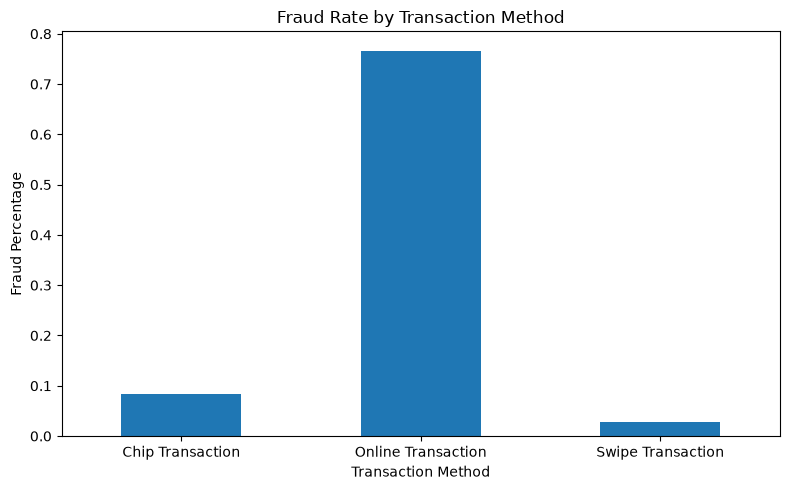

In [17]:
fraud_by_method["fraud_percentage"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Rate by Transaction Method")
plt.xlabel("Transaction Method")
plt.ylabel("Fraud Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
df["amount_group"] = pd.qcut(
    df["amount"],
    q=10,
    duplicates="drop"
)

fraud_by_amount = df.groupby(
    "amount_group",
    observed=True
).agg(
    total_transactions=("fraud_label", "count"),
    fraud_transactions=("fraud_label", "sum")
)

fraud_by_amount["genuine_transactions"] = (
    fraud_by_amount["total_transactions"]
    - fraud_by_amount["fraud_transactions"]
)

fraud_by_amount["fraud_percentage"] = (
    fraud_by_amount["fraud_transactions"]
    / fraud_by_amount["total_transactions"] * 100
)

display(fraud_by_amount)

,total_transactions,fraud_transactions,genuine_transactions,fraud_percentage
amount_group,,,,
"(-500.001, 1.61]",555307,627,554680,0.112911
"(1.61, 5.15]",554761,423,554338,0.076249
"(5.15, 10.9]",554406,434,553972,0.078282
"(10.9, 17.38]",554878,320,554558,0.057670
"(17.38, 26.82]",555159,358,554801,0.064486
"(26.82, 38.18]",554500,413,554087,0.074482
"(38.18, 52.13]",554879,511,554368,0.092092
"(52.13, 70.76]",554808,664,554144,0.119681
"(70.76, 100.0]",601030,860,600170,0.143088


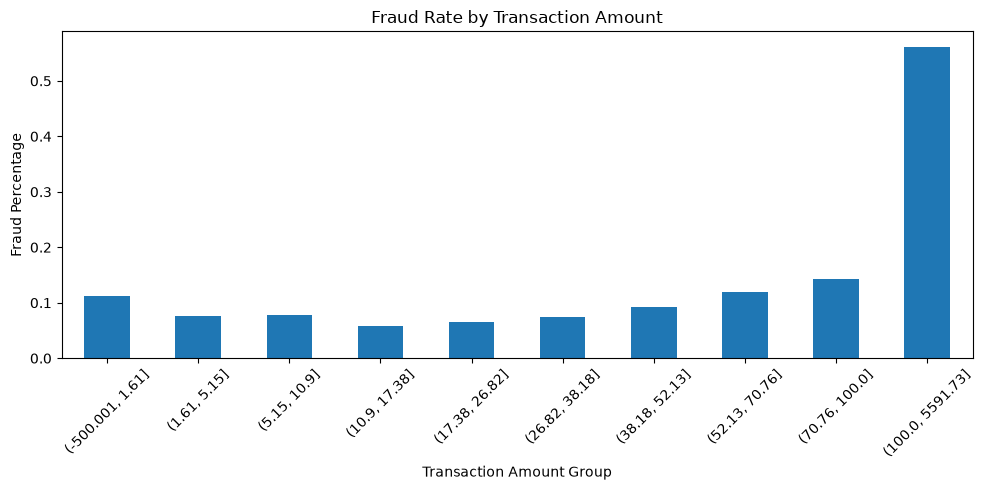

In [19]:
fraud_by_amount["fraud_percentage"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount Group")
plt.ylabel("Fraud Percentage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
df["has_error"] = df["errors"].notna()

fraud_by_error = df.groupby("has_error").agg(
    total_transactions=("fraud_label", "count"),
    fraud_transactions=("fraud_label", "sum")
)

fraud_by_error["fraud_percentage"] = (
    fraud_by_error["fraud_transactions"]
    / fraud_by_error["total_transactions"] * 100
)

display(fraud_by_error)

,total_transactions,fraud_transactions,fraud_percentage
has_error,,,
False,5456466,7129,0.130652
True,91730,335,0.365202


In [21]:
negative_amounts = df[df["amount"] < 0]

print(
    "Negative amount transactions:",
    len(negative_amounts)
)

print("\nFraud distribution:")
display(negative_amounts["fraud_label"].value_counts())

print("\nTransaction methods:")
display(negative_amounts["use_chip"].value_counts())

Negative amount transactions: 274842

Fraud distribution:


fraud_label
False    274574
True        268
Name: count, dtype: int64


Transaction methods:


use_chip
Swipe Transaction     161773
Chip Transaction      110751
Online Transaction      2318
Name: count, dtype: int64

In [22]:
fraud_by_mcc = df.groupby("mcc").agg(
    total_transactions=("fraud_label", "count"),
    fraud_transactions=("fraud_label", "sum")
)

fraud_by_mcc["genuine_transactions"] = (
    fraud_by_mcc["total_transactions"]
    - fraud_by_mcc["fraud_transactions"]
)

fraud_by_mcc["fraud_percentage"] = (
    fraud_by_mcc["fraud_transactions"]
    / fraud_by_mcc["total_transactions"] * 100
)

# Ignore categories with very few transactions
fraud_by_mcc = fraud_by_mcc[
    fraud_by_mcc["total_transactions"] >= 1000
]

fraud_by_mcc = fraud_by_mcc.sort_values(
    "fraud_percentage",
    ascending=False
)

display(fraud_by_mcc.head(15))

,total_transactions,fraud_transactions,genuine_transactions,fraud_percentage
mcc,,,,
5045,1031,116,915,11.251212
5732,2575,228,2347,8.854369
5712,1321,98,1223,7.418622
5816,1005,69,936,6.865672
5094,2021,119,1902,5.888174
5932,2246,42,2204,1.869991
5977,2705,50,2655,1.848429
7996,4041,66,3975,1.633259
3389,3786,61,3725,1.611199


In [23]:
with open(mcc_file, "r") as f:
    mcc_data = json.load(f)

mcc_lookup = {
    int(code): description
    for code, description in mcc_data.items()
}

fraud_by_mcc["merchant_category"] = (
    fraud_by_mcc.index.map(mcc_lookup)
)

display(
    fraud_by_mcc[
        [
            "merchant_category",
            "total_transactions",
            "fraud_transactions",
            "fraud_percentage"
        ]
    ].head(15)
)

,merchant_category,total_transactions,fraud_transactions,fraud_percentage
mcc,,,,
5045,"Computers, Computer Peripheral Equipment",1031,116,11.251212
5732,Electronics Stores,2575,228,8.854369
5712,"Furniture, Home Furnishings, and Equipment Stores",1321,98,7.418622
5816,Digital Goods - Games,1005,69,6.865672
5094,Precious Stones and Metals,2021,119,5.888174
5932,Antique Shops,2246,42,1.869991
5977,Cosmetic Stores,2705,50,1.848429
7996,"Amusement Parks, Carnivals, Circuses",4041,66,1.633259
3389,Non-Precious Metal Services,3786,61,1.611199


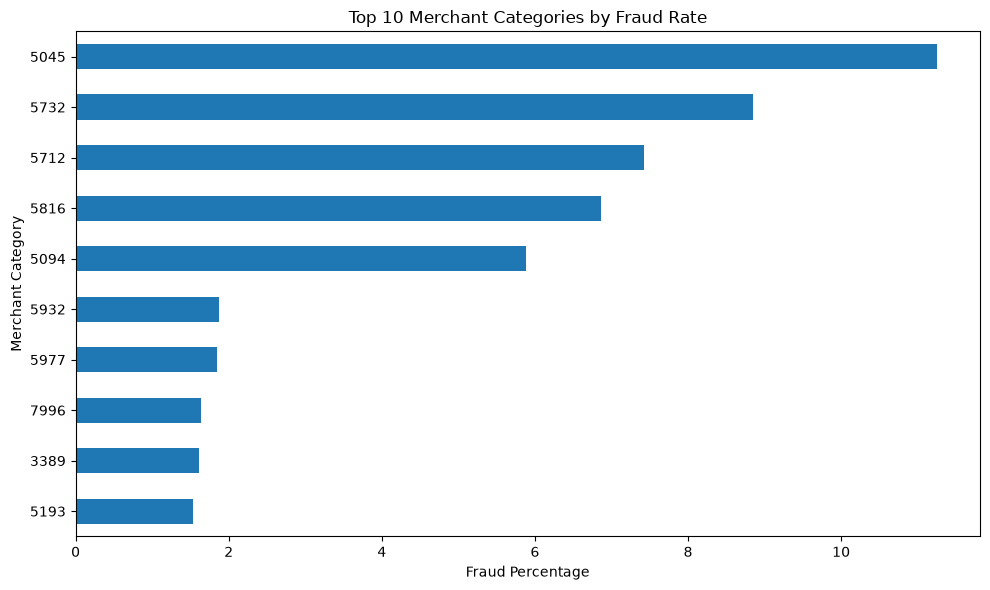

In [24]:
top_mcc = fraud_by_mcc.head(10).sort_values(
    "fraud_percentage"
)

top_mcc["fraud_percentage"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Merchant Categories by Fraud Rate")
plt.xlabel("Fraud Percentage")
plt.ylabel("Merchant Category")
plt.tight_layout()
plt.show()

In [25]:
df["date"] = pd.to_datetime(df["date"])

df["transaction_hour"] = df["date"].dt.hour

print("Date conversion completed.")

Date conversion completed.


In [26]:
fraud_by_hour = df.groupby("transaction_hour").agg(
    total_transactions=("fraud_label", "count"),
    fraud_transactions=("fraud_label", "sum")
)

fraud_by_hour["fraud_percentage"] = (
    fraud_by_hour["fraud_transactions"]
    / fraud_by_hour["total_transactions"] * 100
)

display(fraud_by_hour)

,total_transactions,fraud_transactions,fraud_percentage
transaction_hour,,,
0,61898,9,0.014540
1,43355,22,0.050744
2,44573,21,0.047114
3,40295,62,0.153865
4,46823,78,0.166585
5,80710,146,0.180895
6,327351,250,0.076371
7,372309,305,0.081921
8,370509,299,0.080700


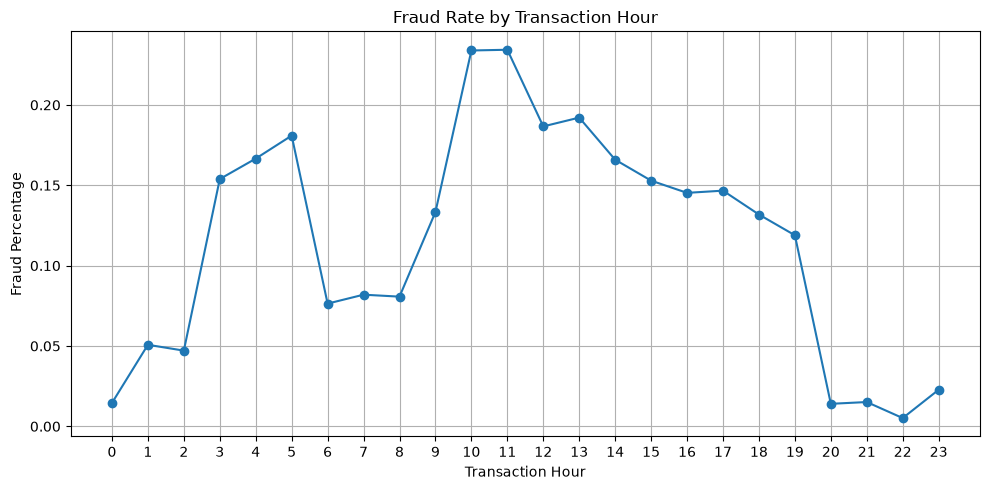

In [27]:
fraud_by_hour["fraud_percentage"].plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Fraud Rate by Transaction Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Percentage")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

# Exploratory Data Analysis – Key Findings

1. The debit dataset contains 5,548,196 labelled transactions.

2. There are 7,464 fraudulent transactions, representing
   approximately 0.1345% of the dataset.

3. Online transactions have a significantly higher fraud
   rate than Chip and Swipe transactions.

4. Higher transaction amounts, particularly amounts above
   100, show a higher fraud rate in this dataset.

5. Transactions with recorded errors show a higher fraud rate,
   although only a small number of fraud cases have errors.

6. Merchant categories and transaction hours may provide
   additional useful information for fraud detection.

7. The dataset is highly imbalanced and requires appropriate
   model evaluation techniques.